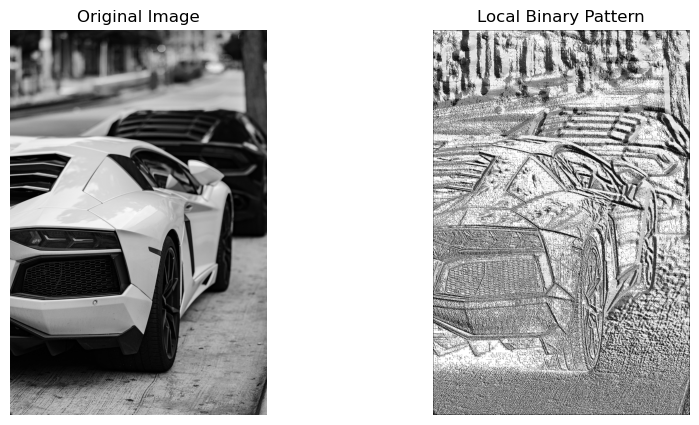

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', 0)

if img is None:
    print("Image not found!")
    exit()
rows, cols = img.shape
lbp = np.zeros((rows, cols), dtype=np.uint8)
for i in range(1, rows - 1):
    for j in range(1, cols - 1):

        center = img[i, j]

        pixels = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        binary = 0

        for k in range(8):
            if pixels[k] >= center:
                binary += 2 ** k

        lbp[i, j] = binary

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title('Local Binary Pattern')
plt.axis('off')
plt.show()

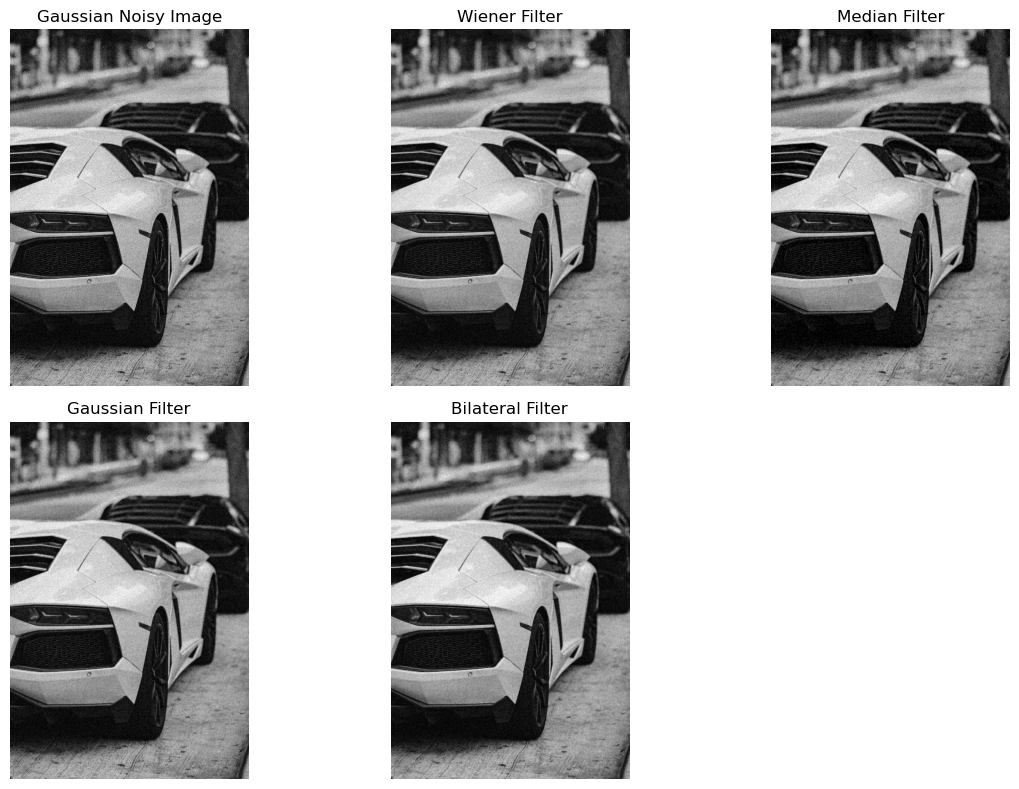

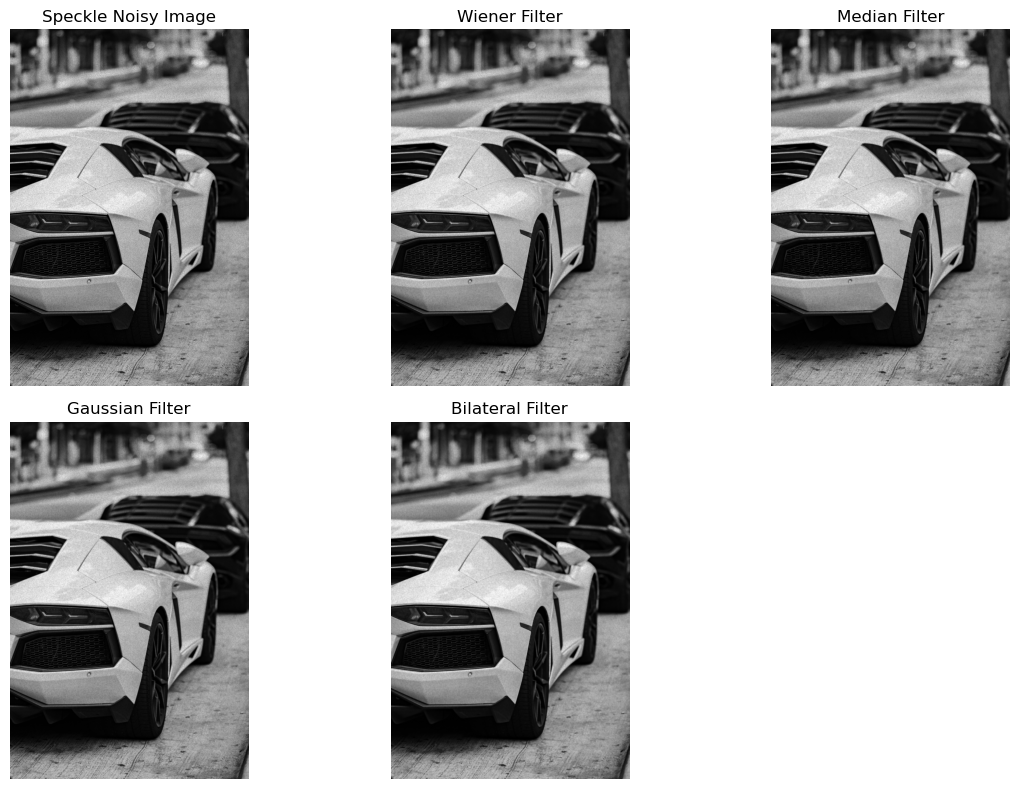

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('car.jpg', 0)

if img is None:
    print("Image not found!")
    exit()

img_float = img.astype(np.float32) / 255.0

gaussian_noise = np.random.normal(0, 0.1, img_float.shape)
gaussian_img = img_float + gaussian_noise
gaussian_img = np.clip(gaussian_img, 0, 1)

speckle_noise = np.random.normal(0, 0.1, img_float.shape)
speckle_img = img_float + img_float * speckle_noise
speckle_img = np.clip(speckle_img, 0, 1)

gaussian_img = np.uint8(gaussian_img * 255)
speckle_img = np.uint8(speckle_img * 255)

def wiener_filter(image, size=3):

    image = image.astype(np.float32)
    mean = cv2.blur(image, (size, size))
    mean_sq = cv2.blur(image * image, (size, size))
    variance = mean_sq - mean * mean
    noise_var = np.mean(variance)
    result = mean + (np.maximum(variance - noise_var, 0) /
                     (variance + 1e-8)) * (image - mean)

    return np.uint8(np.clip(result, 0, 255))

g_wiener = wiener_filter(gaussian_img)
g_median = cv2.medianBlur(gaussian_img, 3)
g_gaussian = cv2.GaussianBlur(gaussian_img, (3, 3), 0)
g_bilateral = cv2.bilateralFilter(gaussian_img, 5, 50, 50)

s_wiener = wiener_filter(speckle_img)
s_median = cv2.medianBlur(speckle_img, 3)
s_gaussian = cv2.GaussianBlur(speckle_img, (3, 3), 0)
s_bilateral = cv2.bilateralFilter(speckle_img, 5, 50, 50)

plt.figure(figsize=(12, 8))

images = [
    gaussian_img, g_wiener, g_median,
    g_gaussian, g_bilateral
]

titles = [
    'Gaussian Noisy Image',
    'Wiener Filter',
    'Median Filter',
    'Gaussian Filter',
    'Bilateral Filter'
]

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()
plt.figure(figsize=(12, 8))

images = [
    speckle_img, s_wiener, s_median,
    s_gaussian, s_bilateral
]

titles = [
    'Speckle Noisy Image',
    'Wiener Filter',
    'Median Filter',
    'Gaussian Filter',
    'Bilateral Filter'
]

for i in range(5):
    plt.subplot(2, 3, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()